In [6]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

class Passenger:
    def __init__(self, seat_row, seat_letter):
        self.target_row = seat_row
        self.target_seat = seat_letter
        self.row = 0          # start at front of plane
        self.seat = None      # not seated yet
        self.seated = False

    def __repr__(self):
        return f"Passenger({self.target_row}{self.target_seat})"


class Plane:
    def __init__(self, num_rows, seat_groups):
        """
        num_rows: int — number of seat rows
        seat_groups: list[int] — e.g. [3, 4, 3] for 10 seats with 2 aisles
        """
        self.num_rows = num_rows
        self.seat_groups = seat_groups
        self.num_aisles = len(seat_groups) - 1

        # make seat labels (A–J)
        letters = "ABCDEFGHIJ"
        self.seat_labels = list(letters[:sum(seat_groups)])

        # y positions for visualization (rows of seats + aisles)
        self.y_positions = []
        y = 0
        for i, group in enumerate(seat_groups):
            for _ in range(group):
                self.y_positions.append(y)
                y += 1
            if i < len(seat_groups) - 1:
                y += 1  # aisle space

        self.aisles = []
        offset = 0
        for size in seat_groups[:-1]:
            offset += size
            self.aisles.append(offset)

        # track seat occupancy
        self.seats = {(r, s): None for r in range(1, num_rows + 1)
                                      for s in self.seat_labels}

    def show(self, passengers=None):
        """Visualize current state of the plane."""
        plt.clf()
        for row in range(1, self.num_rows + 1):
            for i, seat in enumerate(self.seat_labels):
                color = "white"
                if (row, seat) in self.seats and self.seats[(row, seat)] is not None:
                    color = "green"  # occupied
                plt.scatter(row, i, marker="s", s=200, color=color, edgecolor="black")

        # draw aisles
        for a in self.aisles:
            plt.axhline(a - 0.5, color="gray", linewidth=5, alpha=0.5)

        # draw passengers in aisle
        if passengers:
            for p in passengers:
                if not p.seated:
                    plt.scatter(p.row, self.aisles[-1], color="red", s=250, marker="o")

        plt.title("Plane Boarding Simulation")
        plt.xlim(0, self.num_rows + 1)
        plt.ylim(-1, len(self.y_positions))
        plt.gca().invert_yaxis()
        plt.pause(0.2)


    def board_passengers(self, passenger_list):
        """Simulate passengers walking and sitting."""
        plt.ion()
        fig = plt.figure(figsize=(10, 4))

        active = passenger_list.copy()
        for step in range(self.num_rows + 5):
            for p in active:
                if not p.seated:
                    if p.row < p.target_row:
                        p.row += 1  # walk down the aisle
                    else:
                        self.seats[(p.target_row, p.target_seat)] = p
                        p.seated = True
            self.show(passengers=active)
        plt.ioff()
        plt.show()


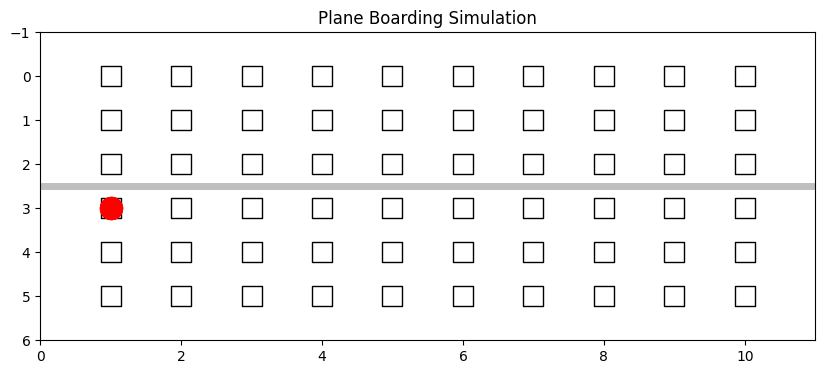

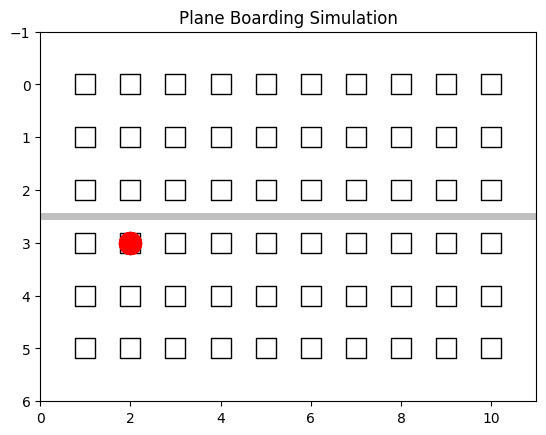

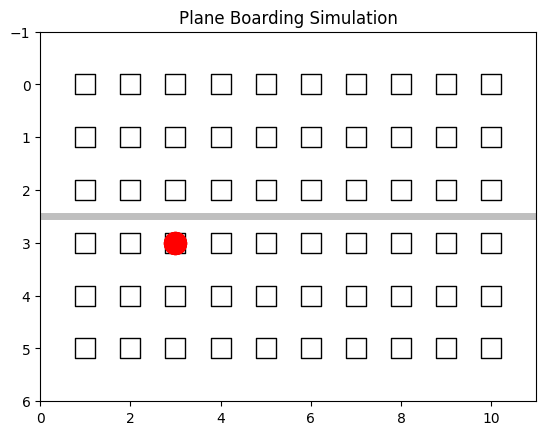

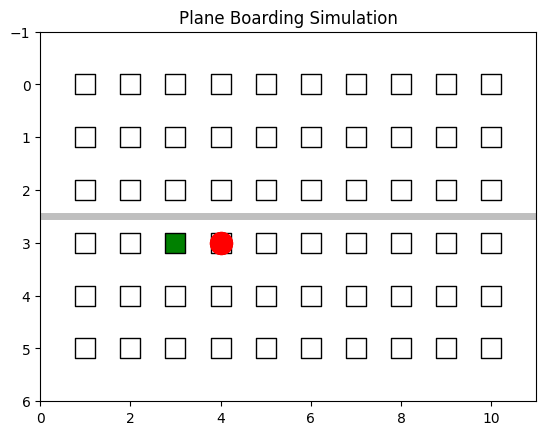

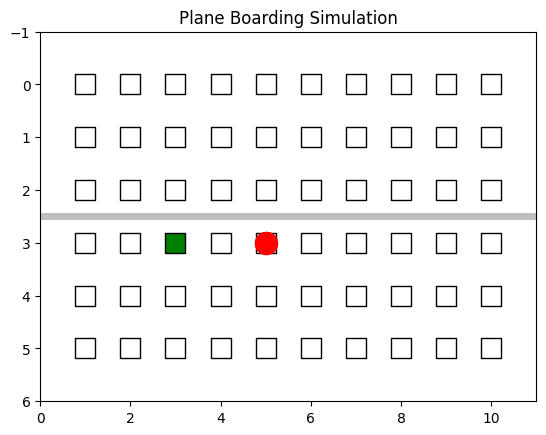

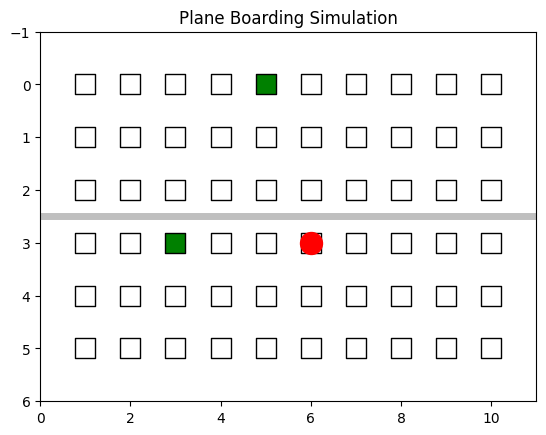

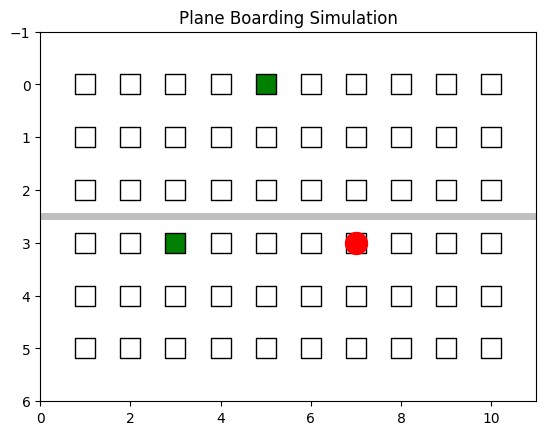

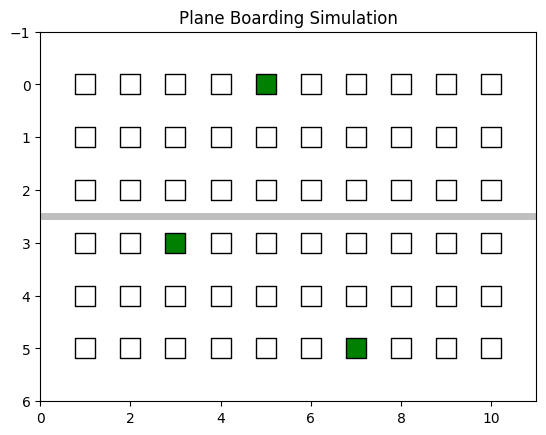

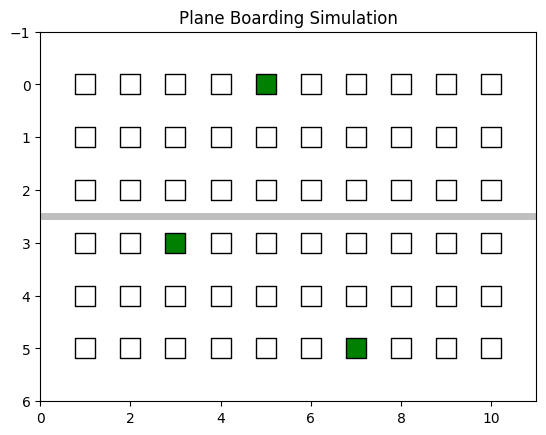

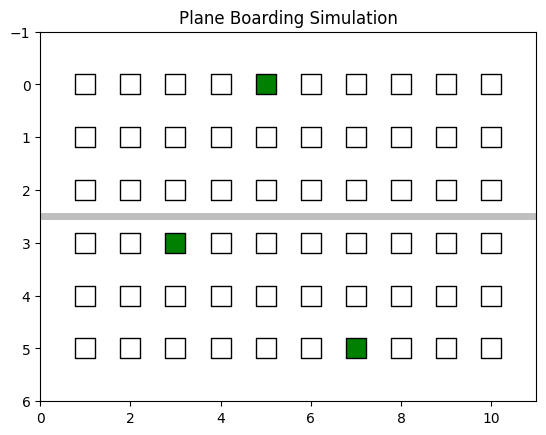

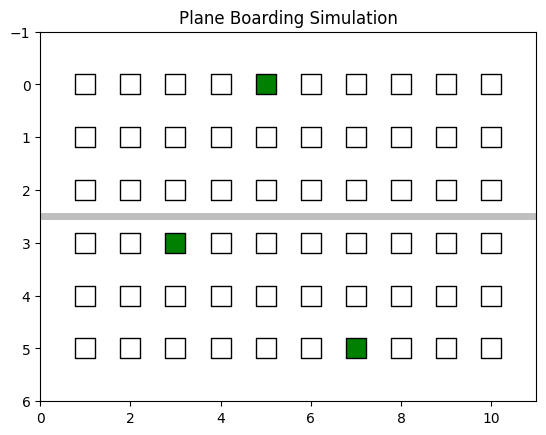

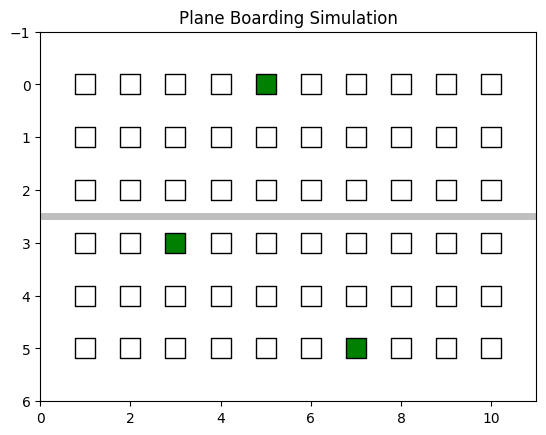

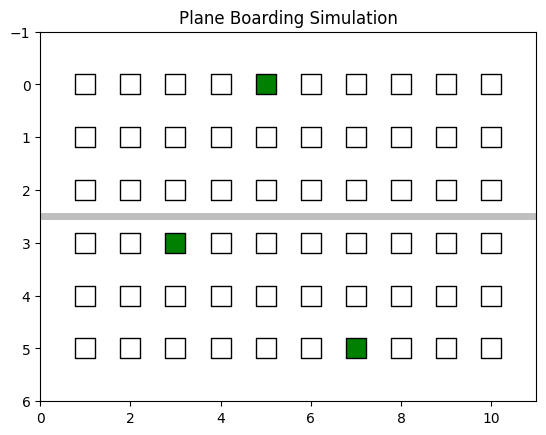

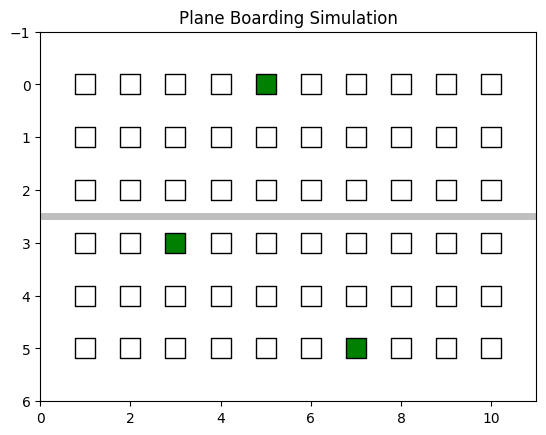

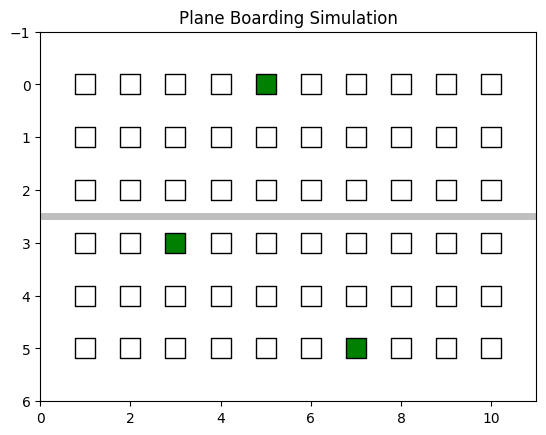

In [8]:
# Example run
# Define plane
plane = Plane(num_rows=10, seat_groups=[3, 3])

# Create passengers (target seat positions)
passengers = [Passenger(5, "A"), Passenger(7, "F"), Passenger(3, "D")]

# Run boarding simulation
plane.board_passengers(passengers)
